# Estrutura do genoma e dos genes de *Colletotrichum abscissum* Ca142

**Montagem:** GCA_023376855.1 · 

**Linhagem:** Ca142 · 

**Anotação:** 15.499 genes codificadores de proteína (MAKER)

Este caderno continua `02_analise_ca142.ipynb`, que baixou, conferiu e fez a primeira contagem dos arquivos.
Aqui passamos das contagens às **distribuições**:

1. Configuração
2. Arquitetura da montagem: como o genoma se distribui entre os scaffolds
3. Leitura da anotação (GFF) em uma tabela
4. Tabela de genes e conferências de consistência
5. Estrutura dos genes: éxons, tamanhos e íntrons
6. Proteínas
7. Genes ao longo do genoma
8. Tabelas salvas
9. Síntese e próximos passos

Ao final, ficam salvas em `data/processed/` tabelas de scaffolds, genes e íntrons, usadas pelos cadernos seguintes
(`04_composicao_ca142.ipynb`, `05_completude_busco_ca142.ipynb` e `06_sintese_ca142.ipynb`) e, mais adiante, pela
busca de alvos de RNAi.

## 1. Configuração

Bibliotecas novas em relação aos cadernos anteriores:

- **`numpy`**: operações numéricas sobre vetores (usado para faixas logarítmicas nos histogramas);
- **`matplotlib`**: gráficos;
- **`urllib.parse.unquote`**: decodifica caracteres especiais nos atributos do GFF (seção 3).

A função `estilo()` define uma aparência única para todos os gráficos: fundo claro, grade discreta, só os eixos
esquerdo e inferior, e uma cor principal (azul). Cada gráfico também é salvo em `results/figures/`.

In [1]:
import re
from collections import Counter
from pathlib import Path
from urllib.parse import unquote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO
from Bio.Seq import Seq

ACCESSION = "GCA_023376855.1"   # Ca142, escolhida em 01_selecao_montagem.ipynb

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DADOS = RAIZ / "data" / "raw" / "ca142" / "ncbi_dataset" / "data" / ACCESSION
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_PROC.mkdir(parents=True, exist_ok=True)
DIR_FIG.mkdir(parents=True, exist_ok=True)

ARQ_GENOMA = next(DIR_DADOS.glob(f"{ACCESSION}_*_genomic.fna"))
ARQ_GFF = DIR_DADOS / "genomic.gff"
ARQ_PROT = DIR_DADOS / "protein.faa"
ARQ_CDS = DIR_DADOS / "cds_from_genomic.fna"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Cores e estilo dos gráficos
AZUL = "#2a78d6"       # cor principal
LARANJA = "#eb6834"    # segunda categoria, quando houver
TINTA = "#0b0b0b"      # texto principal
TINTA_2 = "#52514e"    # texto secundário, eixos
GRADE = "#e4e3df"
FUNDO = "#fcfcfb"

def estilo():
    plt.rcParams.update({
        "figure.figsize": (7.5, 4.2), "figure.dpi": 110, "savefig.dpi": 200,
        "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
        "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "xtick.color": TINTA_2, "ytick.color": TINTA_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
        "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
    })

def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png", bbox_inches="tight")

def eixo_log(ax, compacto=True):
    """Eixo x em escala log com rótulos legíveis (1, 2, 5, 10, 20, 50…), em vez de potências de 10."""
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
    def rotulo(v, _):
        if compacto and v >= 1e6:
            return f"{v / 1e6:g} Mb"
        if compacto and v >= 1e3:
            return f"{v / 1e3:g} kb"
        return fmt(v)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(rotulo))
    ax.xaxis.set_minor_formatter(NullFormatter())

def marcar_mediana(ax, valor, unidade):
    """Linha tracejada na mediana, com o rótulo do lado que tiver mais espaço."""
    ax.set_ylim(top=ax.get_ylim()[1] * 1.12)               # abre espaço acima das barras para o rótulo
    pos = ax.transAxes.inverted().transform(ax.transData.transform((valor, 0)))[0]
    lado = (-6, "right") if pos > 0.6 else (6, "left")
    ax.axvline(valor, color=TINTA, linewidth=1, linestyle=(0, (3, 3)))
    ax.annotate(f"mediana = {valor:.0f} {unidade}", (valor, 0.95), xycoords=("data", "axes fraction"),
                xytext=(lado[0], 0), textcoords="offset points", ha=lado[1], color=TINTA, fontsize=9)

def fmt(n):
    """Formata inteiros com ponto como separador de milhar."""
    return f"{n:,.0f}".replace(",", ".")

estilo()
print("Dados em:", DIR_DADOS.relative_to(RAIZ))

Dados em: data/raw/ca142/ncbi_dataset/data/GCA_023376855.1


## 2. Arquitetura da montagem

No caderno anterior vimos os números gerais (423 scaffolds, 54,0 Mb, N50 de 321.765 pb). Agora olhamos **como o
genoma se distribui** entre os scaffolds.

Primeiro, refazemos a tabela de scaffolds (tamanho, contagem de bases e GC). Também guardamos a sequência de cada
scaffold em um dicionário, `genoma`, para consultar trechos do genoma mais adiante (na seção 5, para examinar as
bordas dos íntrons).

In [2]:
genoma = {}
linhas = []
for reg in SeqIO.parse(ARQ_GENOMA, "fasta"):
    s = str(reg.seq).upper()
    genoma[reg.id] = s
    linhas.append({"scaffold": reg.id, "tamanho": len(s),
                   "A": s.count("A"), "C": s.count("C"), "G": s.count("G"), "T": s.count("T"),
                   "N": s.count("N")})

df_scaf = pd.DataFrame(linhas).sort_values("tamanho", ascending=False, ignore_index=True)
df_scaf["gc"] = (df_scaf["G"] + df_scaf["C"]) / df_scaf[["A", "C", "G", "T"]].sum(axis=1)
df_scaf["posto"] = np.arange(1, len(df_scaf) + 1)                      # 1 = maior scaffold
df_scaf["acumulado"] = df_scaf["tamanho"].cumsum() / df_scaf["tamanho"].sum()

TOTAL = df_scaf["tamanho"].sum()
print(f"{len(df_scaf)} scaffolds, {fmt(TOTAL)} pb")

423 scaffolds, 54.001.896 pb


### 2.1 Curva de contiguidade (Nx)

O N50 é um único ponto de uma curva. Ordenando os scaffolds do maior para o menor e acumulando seus tamanhos,
a curva mostra **que fração do genoma está contida nos *k* maiores scaffolds**.

- **N50 / L50**: o ponto em que a curva cruza 50% — o tamanho do scaffold nesse ponto (N50) e quantos scaffolds
  foram necessários (L50).
- **N90 / L90**: a mesma ideia para 90% do genoma. Mostra quanto do genoma está em pedaços pequenos.

Uma curva que sobe rápido e logo se achata indica uma montagem contígua; uma curva que sobe devagar indica um
genoma espalhado em muitos pedaços.

In [3]:
def nx_lx(df, fracao):
    linha = df[df["acumulado"] >= fracao].iloc[0]
    return int(linha["tamanho"]), int(linha["posto"])

tabela_nx = pd.DataFrame(
    [(f"N{int(f * 100)}", *nx_lx(df_scaf, f)) for f in (0.5, 0.75, 0.9)],
    columns=["métrica", "tamanho do scaffold (pb)", "nº de scaffolds (L)"],
).set_index("métrica")
tabela_nx

,tamanho do scaffold (pb),nº de scaffolds (L)
métrica,,
N50,321765,46
N75,162847,104
N90,74130,177


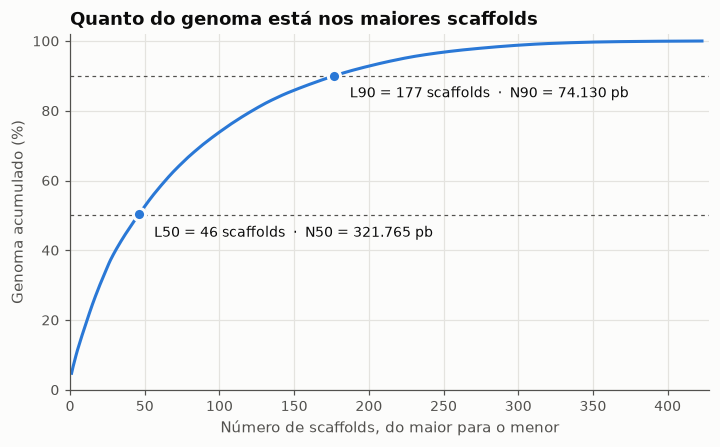

In [4]:
n50, l50 = nx_lx(df_scaf, 0.5)
n90, l90 = nx_lx(df_scaf, 0.9)

fig, ax = plt.subplots()
ax.plot(df_scaf["posto"], 100 * df_scaf["acumulado"], color=AZUL, linewidth=2)
for (n, l, f) in [(n50, l50, 50), (n90, l90, 90)]:
    ax.axhline(f, color=TINTA_2, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.plot(l, 100 * df_scaf.loc[l - 1, "acumulado"], "o", color=AZUL, markersize=8,
            markeredgecolor=FUNDO, markeredgewidth=2)
    ax.annotate(f"L{f} = {l} scaffolds  ·  N{f} = {fmt(n)} pb", (l, f),
                xytext=(10, -14), textcoords="offset points", color=TINTA, fontsize=9)
ax.set_xlabel("Número de scaffolds, do maior para o menor")
ax.set_ylabel("Genoma acumulado (%)")
ax.set_ylim(0, 102)
ax.set_xlim(0, len(df_scaf) + 5)
ax.set_title("Quanto do genoma está nos maiores scaffolds")
salvar(fig, "03_curva_nx")
plt.show()

**Resultado**

- **Metade do genoma está em 46 scaffolds** de 322 kb ou mais (N50/L50), e **90% em 177 scaffolds** de 74 kb ou mais
  (N90/L90).
- A curva sobe rápido no começo e depois se arrasta: os últimos 246 scaffolds (58% deles) somam só 10% do genoma.
- É uma contiguidade típica de montagem feita só com leituras curtas. Para comparação, a LW-VAL-2A (PacBio) tem o
  genoma inteiro em 50 scaffolds, com N50 de 4,5 Mb.

### 2.2 Distribuição dos tamanhos

Os tamanhos de scaffolds variam de ~1 kb a ~2,5 Mb — três ordens de grandeza. Num histograma comum, quase tudo
ficaria espremido na primeira barra. Por isso usamos **escala logarítmica** no eixo x: cada intervalo do
histograma cobre a mesma *proporção* de tamanho (por exemplo, de 1 a 2 kb e de 100 a 200 kb), e não a mesma
quantidade de pares de bases.

A tabela ao lado responde a uma pergunta prática: **os scaffolds pequenos são muitos, mas quanto do genoma eles
representam?**

In [5]:
faixas = [0, 10_000, 50_000, 100_000, 500_000, np.inf]
rotulos = ["< 10 kb", "10–50 kb", "50–100 kb", "100–500 kb", "≥ 500 kb"]
df_scaf["faixa"] = pd.cut(df_scaf["tamanho"], faixas, labels=rotulos, right=False)

por_faixa = df_scaf.groupby("faixa", observed=False).agg(
    scaffolds=("tamanho", "size"), pb=("tamanho", "sum"))
por_faixa["% dos scaffolds"] = (100 * por_faixa["scaffolds"] / len(df_scaf)).round(1)
por_faixa["% do genoma"] = (100 * por_faixa["pb"] / TOTAL).round(1)
por_faixa

,scaffolds,pb,% dos scaffolds,% do genoma
faixa,,,,
< 10 kb,105,409957,24.8,0.8
10–50 kb,105,2771467,24.8,5.1
50–100 kb,70,5102577,16.5,9.4
100–500 kb,116,25650143,27.4,47.5
≥ 500 kb,27,20067752,6.4,37.2


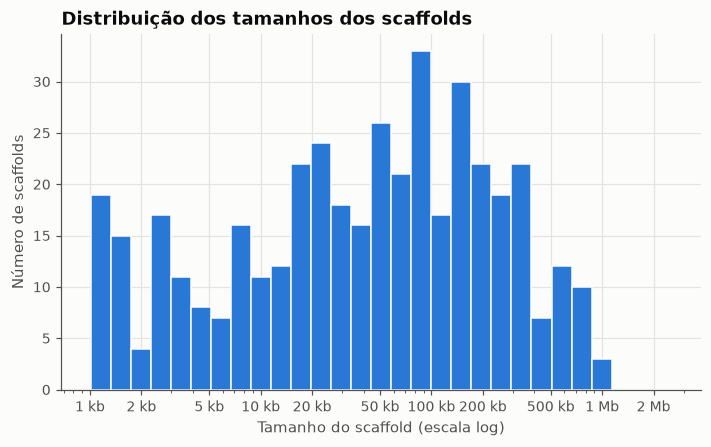

In [6]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(df_scaf["tamanho"].min()), np.log10(df_scaf["tamanho"].max()), 30)
ax.hist(df_scaf["tamanho"], bins=bins, color=AZUL, edgecolor=FUNDO, linewidth=1)
eixo_log(ax)
ax.set_xlabel("Tamanho do scaffold (escala log)")
ax.set_ylabel("Número de scaffolds")
ax.set_title("Distribuição dos tamanhos dos scaffolds")
salvar(fig, "03_tamanho_scaffolds")
plt.show()

**Resultado**

- **Os scaffolds pequenos são muitos, mas pesam pouco:** 105 scaffolds (25%) têm menos de 10 kb e somam só **0,8%**
  do genoma. Metade dos scaffolds (210) tem menos de 50 kb e soma 5,9%.
- **O genoma está nos scaffolds grandes:** os 143 scaffolds de 100 kb ou mais concentram **84,7%** das bases; os 27
  de 500 kb ou mais, 37,2%.
- No histograma, a distribuição é larga, sem um tamanho típico: há scaffolds em todas as faixas, de 1 kb a 1 Mb, e
  um único acima de 2 Mb.

Consequência prática: análises que dependem da vizinhança dos genes (seção 7 e caderno 04) são confiáveis para a
grande maioria do genoma, mas não para os scaffolds de poucos kb.

## 3. Leitura da anotação (GFF) em uma tabela

No caderno anterior lemos só a 3ª coluna do GFF. Agora lemos **todas as 9 colunas** para uma tabela do pandas.

A 9ª coluna (*attributes*) é um texto com pares `chave=valor` separados por `;`, por exemplo:

```
ID=cds-KAI0000001.1;Parent=rna-xxx;locus_tag=CABS01_000001;product=MFS transporter%2C sugar porter
```

Dois detalhes:

- A função `ler_atributos` transforma esse texto em um dicionário do Python (`{"ID": "...", "Parent": "..."}`);
- Caracteres que têm significado especial no GFF (`;`, `=`, `,`) aparecem **codificados** dentro dos valores: `%2C`
  é a vírgula, `%3B` o ponto e vírgula. A função `unquote` devolve o caractere original.

Depois, criamos colunas separadas só para os atributos que vamos usar.

In [7]:
COLUNAS_GFF = ["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"]

def ler_atributos(texto):
    pares = {}
    for item in texto.strip().split(";"):
        if "=" in item:
            chave, valor = item.split("=", 1)
            pares[chave] = unquote(valor)
    return pares

registros = []
with open(ARQ_GFF) as f:
    for linha in f:
        if linha.startswith("##FASTA"):
            break
        if linha.startswith("#") or not linha.strip():
            continue
        registros.append(linha.rstrip("\n").split("\t"))

gff = pd.DataFrame(registros, columns=COLUNAS_GFF)
gff["start"] = gff["start"].astype(int)
gff["end"] = gff["end"].astype(int)
gff["tamanho"] = gff["end"] - gff["start"] + 1        # coordenadas do GFF incluem início e fim

atributos = gff["attributes"].map(ler_atributos)
for chave in ["ID", "Parent", "locus_tag", "protein_id", "product", "partial", "gene_biotype"]:
    gff[chave] = atributos.map(lambda d, k=chave: d.get(k))

print(f"{fmt(len(gff))} linhas")
gff.drop(columns="attributes").head(8)

117.161 linhas


,seqid,source,type,start,end,score,strand,phase,tamanho,ID,Parent,locus_tag,protein_id,product,partial,gene_biotype
0,SDAQ01000001.1,Genbank,region,1,2556205,.,+,.,2556205,SDAQ01000001.1:1..2556205,NaN,NaN,NaN,NaN,NaN,NaN
1,SDAQ01000001.1,Genbank,gene,11380,13054,.,-,.,1675,gene-CABS02_00001,NaN,CABS02_00001,NaN,NaN,NaN,protein_coding
2,SDAQ01000001.1,Genbank,mRNA,11380,13054,.,-,.,1675,rna-gnl|WGS:SDAQ|mrna.CABS02_00001,gene-CABS02_00001,CABS02_00001,NaN,hypothetical protein,NaN,NaN
3,SDAQ01000001.1,Genbank,exon,11710,13054,.,-,.,1345,exon-gnl|WGS:SDAQ|mrna.CABS02_00001-1,rna-gnl|WGS:SDAQ|mrna.CABS02_00001,CABS02_00001,NaN,hypothetical protein,NaN,NaN
4,SDAQ01000001.1,Genbank,exon,11380,11657,.,-,.,278,exon-gnl|WGS:SDAQ|mrna.CABS02_00001-2,rna-gnl|WGS:SDAQ|mrna.CABS02_00001,CABS02_00001,NaN,hypothetical protein,NaN,NaN
5,SDAQ01000001.1,Genbank,CDS,11710,13054,.,-,0,1345,cds-KAI3559026.1,rna-gnl|WGS:SDAQ|mrna.CABS02_00001,CABS02_00001,KAI3559026.1,hypothetical protein,NaN,NaN
6,SDAQ01000001.1,Genbank,CDS,11380,11657,.,-,2,278,cds-KAI3559026.1,rna-gnl|WGS:SDAQ|mrna.CABS02_00001,CABS02_00001,KAI3559026.1,hypothetical protein,NaN,NaN
7,SDAQ01000001.1,Genbank,gene,13450,20339,.,+,.,6890,gene-CABS02_00002,NaN,CABS02_00002,NaN,NaN,NaN,protein_coding


**Resultado:** a tabela tem **117.161 linhas**, exatamente a soma das contagens do caderno 02 (423 `region` +
15.499 `gene` + 15.499 `mRNA` + 42.870 `exon` + 42.870 `CDS`).

As primeiras linhas mostram o primeiro gene, `CABS02_00001`, na fita negativa do scaffold `SDAQ01000001.1`: um mRNA,
dois éxons e dois trechos de CDS com as mesmas coordenadas dos éxons. Repare em três detalhes:

- os identificadores seguem um padrão: `gene-CABS02_00001`, `rna-gnl|WGS:SDAQ|mrna.CABS02_00001`, `cds-KAI3559026.1`;
- o `protein_id` (`KAI3559026.1`) só aparece nas linhas de CDS, e o nome do produto, nas linhas de mRNA, éxon e CDS;
- em genes da fita negativa, o NCBI lista os éxons na ordem da transcrição (da coordenada maior para a menor).

Para ver todos os atributos de um elemento, por exemplo o primeiro gene:
`atributos[gff.index[gff["type"] == "gene"][0]]`

### 3.1 A anotação inclui UTRs?

Vimos que há o mesmo número de linhas `exon` e `CDS` (42.870). Se as UTRs (regiões não traduzidas nas pontas do
mRNA) estivessem anotadas, o primeiro e o último éxon de muitos genes seriam **maiores** que o trecho de CDS
correspondente. Comparamos as coordenadas: se todo éxon coincidir com um trecho de CDS, a anotação não tem UTRs.

In [8]:
chave = ["seqid", "start", "end", "strand"]
exons_coord = set(map(tuple, gff.loc[gff["type"] == "exon", chave].values))
cds_coord = set(map(tuple, gff.loc[gff["type"] == "CDS", chave].values))

print("Éxons idênticos a um trecho de CDS:", fmt(len(exons_coord & cds_coord)))
print("Éxons sem CDS correspondente:      ", fmt(len(exons_coord - cds_coord)))

Éxons idênticos a um trecho de CDS: 42.870
Éxons sem CDS correspondente:       0


**Resultado:** os 42.870 éxons têm coordenadas idênticas às de um trecho de CDS, e nenhum fica sem correspondência.
**A anotação não tem UTRs:** cada éxon vai exatamente do início ao fim do trecho codificador.

Consequências:

- na Ca142, só conhecemos a parte codificadora dos mRNAs; o desenho de dsRNA fica restrito à CDS;
- o "tamanho do gene" medido aqui vai do códon de início ao de parada, e é menor que o do transcrito real.

### 3.2 Genes parciais

Um gene é **parcial** quando o modelo anotado não tem o códon de início, o códon de parada, ou nenhum dos dois. O
NCBI marca esses casos com o atributo `partial=true`. Há duas causas possíveis:

- **o gene está cortado pela montagem:** começa ou termina na ponta de um scaffold ou numa lacuna (`N`);
- **o modelo de gene está incompleto:** o programa de predição não encontrou o início ou o fim, embora a sequência
  ao redor exista.

Genes parciais não devem entrar nas estatísticas de tamanho como se estivessem completos, e são **maus candidatos a
alvos de RNAi** enquanto a sequência completa não for conhecida. A seção 4.2 examina onde eles estão.

In [9]:
genes_gff = gff[gff["type"] == "gene"]
mrnas_gff = gff[gff["type"] == "mRNA"]

parcial_gene = set(genes_gff.loc[genes_gff["partial"] == "true", "ID"])
parcial_mrna = set(mrnas_gff.loc[mrnas_gff["partial"] == "true", "Parent"])
genes_parciais = parcial_gene | parcial_mrna

print(f"Genes parciais: {fmt(len(genes_parciais))} de {fmt(len(genes_gff))} "
      f"({100 * len(genes_parciais) / len(genes_gff):.1f}%)")

Genes parciais: 215 de 15.499 (1.4%)


**Resultado:** **215 genes parciais (1,4%)**. É pouco: 98,6% dos modelos de genes têm início e fim anotados.

## 4. Tabela de genes

Agora juntamos as linhas do GFF em **uma linha por gene**, usando a hierarquia `gene → mRNA → exon/CDS` (os
atributos `ID` e `Parent`). Como cada gene tem um único mRNA, uma linha por mRNA é o mesmo que uma linha por gene.

Para cada gene calculamos:

| Coluna | Como é calculada |
|---|---|
| `tam_gene` | do início ao fim do mRNA no genoma (éxons + íntrons) |
| `n_exons` | número de linhas `exon` do mRNA |
| `tam_cds` | soma dos trechos de CDS (inclui o códon de parada) |
| `tam_introns` | `tam_gene` − soma dos éxons |
| `protein_id`, `produto` | atributos do CDS |
| `parcial` | gene marcado como parcial (seção 3.2) |

`groupby("Parent")` agrupa os éxons (ou as CDS) pelo mRNA a que pertencem, e `agg` resume cada grupo.

In [10]:
mrna = mrnas_gff[["ID", "Parent", "locus_tag", "seqid", "start", "end", "strand"]].rename(
    columns={"ID": "mrna_id", "Parent": "gene_id", "start": "inicio", "end": "fim", "strand": "fita"})

exons = gff[gff["type"] == "exon"]
resumo_exons = exons.groupby("Parent").agg(n_exons=("tamanho", "size"), soma_exons=("tamanho", "sum"))

cds = gff[gff["type"] == "CDS"]
resumo_cds = cds.groupby("Parent").agg(tam_cds=("tamanho", "sum"), n_trechos_cds=("tamanho", "size"),
                                      protein_id=("protein_id", "first"), produto=("product", "first"))

genes = (mrna.merge(resumo_exons, left_on="mrna_id", right_index=True, how="left")
             .merge(resumo_cds, left_on="mrna_id", right_index=True, how="left"))
genes["tam_gene"] = genes["fim"] - genes["inicio"] + 1
genes["tam_introns"] = genes["tam_gene"] - genes["soma_exons"]
genes["parcial"] = genes["gene_id"].isin(genes_parciais)
genes = genes.sort_values(["seqid", "inicio"], ignore_index=True)

print(fmt(len(genes)), "genes")
genes[["locus_tag", "seqid", "inicio", "fim", "fita", "n_exons", "tam_gene", "tam_cds",
       "tam_introns", "protein_id", "produto", "parcial"]].head()

15.499 genes


,locus_tag,seqid,inicio,fim,fita,n_exons,tam_gene,tam_cds,tam_introns,protein_id,produto,parcial
0,CABS02_00001,SDAQ01000001.1,11380,13054,-,2,1675,1623,52,KAI3559026.1,hypothetical protein,False
1,CABS02_00002,SDAQ01000001.1,13450,20339,+,4,6890,6726,164,KAI3559027.1,serine/threonine protein kinase,False
2,CABS02_00003,SDAQ01000001.1,21470,22384,+,1,915,915,0,KAI3559028.1,alpha/beta hydrolase fold,False
3,CABS02_00004,SDAQ01000001.1,25110,26677,+,3,1568,1428,140,KAI3559029.1,hypothetical protein,False
4,CABS02_00005,SDAQ01000001.1,31608,33260,+,4,1653,1476,177,KAI3559030.1,G-protein coupled receptor,False


**Resultado:** a tabela tem 15.499 linhas, uma por gene, em ordem de posição no genoma. Nos cinco primeiros genes do
maior scaffold já aparece a variedade: de 1 a 4 éxons, CDS de 915 a 6.726 pb, e produtos com nome
("serine/threonine protein kinase") ao lado de proteínas hipotéticas.

### 4.1 Conferências de consistência

Antes de tirar conclusões, conferimos se os três arquivos de anotação contam a mesma história:

1. **A CDS tem tamanho múltiplo de 3?** Cada códon tem 3 bases; uma CDS completa precisa ser múltipla de 3.
2. **O tamanho da CDS no GFF bate com o `cds_from_genomic.fna`?** Ligamos os dois pelo `protein_id`.
3. **CDS = 3 × proteína + 3?** A proteína não inclui o códon de parada; a CDS inclui. Para um gene completo,
   `tam_cds = 3 × tam_proteina + 3`.
4. **A CDS começa com ATG e termina em um códon de parada (TAA, TAG ou TGA)?**

Os genes que falham costumam ser os **parciais**, por isso a tabela separa os dois grupos.

In [11]:
# Sequências de CDS (o protein_id está no cabeçalho, entre colchetes)
seq_cds = {}
for reg in SeqIO.parse(ARQ_CDS, "fasta"):
    m = re.search(r"\[protein_id=([^\]]+)\]", reg.description)
    if m:
        seq_cds[m.group(1)] = str(reg.seq).upper()

# Proteínas (o identificador é o protein_id)
seq_prot = {reg.id: str(reg.seq) for reg in SeqIO.parse(ARQ_PROT, "fasta")}

genes["tam_cds_fasta"] = genes["protein_id"].map(lambda p: len(seq_cds[p]) if p in seq_cds else np.nan)
genes["tam_proteina"] = genes["protein_id"].map(lambda p: len(seq_prot[p]) if p in seq_prot else np.nan)

PARADA = {"TAA", "TAG", "TGA"}
inicio_atg = genes["protein_id"].map(lambda p: seq_cds.get(p, "")[:3] == "ATG")
fim_parada = genes["protein_id"].map(lambda p: seq_cds.get(p, "")[-3:] in PARADA)

testes = pd.DataFrame({
    "CDS múltipla de 3": genes["tam_cds"] % 3 == 0,
    "GFF = cds_from_genomic": genes["tam_cds"] == genes["tam_cds_fasta"],
    "CDS = 3 × proteína + 3": genes["tam_cds"] == 3 * genes["tam_proteina"] + 3,
    "começa com ATG": inicio_atg,
    "termina em códon de parada": fim_parada,
})

conferencia = pd.DataFrame({
    "completos (% ok)": (100 * testes[~genes["parcial"]].mean()).round(2),
    "parciais (% ok)": (100 * testes[genes["parcial"]].mean()).round(2),
})
conferencia

,completos (% ok),parciais (% ok)
CDS múltipla de 3,100.0,92.09
GFF = cds_from_genomic,100.0,98.60
CDS = 3 × proteína + 3,100.0,81.40
começa com ATG,100.0,16.28
termina em códon de parada,100.0,83.26


**Resultado**

**Genes completos (15.284): 100% em todas as conferências.** Toda CDS tem tamanho múltiplo de 3, começa com ATG,
termina em códon de parada, tem o mesmo tamanho no GFF e no `cds_from_genomic.fna` e corresponde exatamente à
proteína de `protein.faa`. Os três arquivos de anotação contam a mesma história, e o quadro de leitura está
preservado em todos os genes completos.

**Genes parciais (215):** as falhas mostram o que falta em cada um.

- Só 16% começam com ATG: **180 não têm o códon de início** (falta a extremidade 5').
- 83% terminam em códon de parada: **36 não têm o códon de parada** (falta a extremidade 3').
- 17 têm CDS com tamanho não múltiplo de 3: a sequência começa no meio de um códon.
- 3 têm tamanho diferente entre o GFF e o FASTA de CDS.

A grande maioria dos genes parciais, portanto, é de genes **sem início**. A seção 4.2 verifica se isso se deve à
fragmentação da montagem.

A partir daqui, as estatísticas de tamanho usam **só os genes completos**.

In [12]:
completos = genes[~genes["parcial"]].copy()
print(f"Genes completos: {fmt(len(completos))}  ·  parciais: {fmt(genes['parcial'].sum())}")

Genes completos: 15.284  ·  parciais: 215


### 4.2 Onde estão os genes parciais?

Para saber por que um gene é parcial, cruzamos duas informações:

- **qual extremidade falta.** O GFF marca a ponta incompleta com os atributos `start_range` (falta a ponta de
  coordenada menor) e `end_range` (falta a de coordenada maior). Num gene da fita `+`, a coordenada menor é a
  extremidade 5'; num gene da fita `−`, é a 3'.
- **onde o gene está.** Medimos a distância até a ponta mais próxima do scaffold e procuramos lacunas (`N`) a até
  100 pb do gene.

Se a maioria dos genes parciais estiver **na borda** de um scaffold ou junto a uma lacuna, a causa é a fragmentação
da montagem, e esses genes devem aparecer completos em uma montagem mais contígua (como a LW-VAL-2A). Se estiverem
**no interior** dos scaffolds, a causa é o modelo de gene, e o problema é da anotação.

In [13]:
# Extremidades marcadas como incompletas no GFF (nas linhas de gene ou de mRNA)
falta_menor, falta_maior = set(), set()
for tabela, coluna in [(genes_gff, "ID"), (mrnas_gff, "Parent")]:
    for gene_id, attrs in zip(tabela[coluna], atributos[tabela.index]):
        if "start_range" in attrs:
            falta_menor.add(gene_id)
        if "end_range" in attrs:
            falta_maior.add(gene_id)

tam_scaf = df_scaf.set_index("scaffold")["tamanho"]
MARGEM = 100   # pb

parc = genes[genes["parcial"]].copy()
menor = parc["gene_id"].isin(falta_menor)
maior = parc["gene_id"].isin(falta_maior)
parc["falta_5"] = np.where(parc["fita"] == "+", menor, maior)
parc["falta_3"] = np.where(parc["fita"] == "+", maior, menor)
parc["extremidade"] = np.select(
    [parc["falta_5"] & parc["falta_3"], parc["falta_5"], parc["falta_3"]],
    ["5' e 3'", "só 5' (sem início)", "só 3' (sem fim)"], default="não indicada")

parc["dist_borda"] = np.minimum(parc["inicio"] - 1, parc["seqid"].map(tam_scaf) - parc["fim"])
perto_de_n = [("N" in genoma[g.seqid][max(0, g.inicio - 1 - MARGEM):g.fim + MARGEM]) for g in parc.itertuples()]
parc["local"] = np.select(
    [parc["dist_borda"] <= MARGEM, perto_de_n],
    [f"na borda do scaffold (≤ {MARGEM} pb)", f"junto a uma lacuna (N a ≤ {MARGEM} pb)"],
    default="no interior do scaffold")

display(pd.crosstab(parc["extremidade"], parc["local"], margins=True, margins_name="total"))
print(f"Distância mediana até a borda do scaffold: {fmt(parc['dist_borda'].median())} pb")

local,junto a uma lacuna (N a ≤ 100 pb),na borda do scaffold (≤ 100 pb),no interior do scaffold,total
extremidade,,,,
5' e 3',0,1,1,2
só 3' (sem fim),0,30,5,35
só 5' (sem início),1,14,163,178
total,1,45,169,215


Distância mediana até a borda do scaffold: 31.747 pb


**Resultado: a maioria dos genes parciais é falha do modelo de gene, não da montagem.**

- **169 dos 215 genes parciais (79%) estão no interior dos scaffolds**, longe de bordas e de lacunas. A distância
  mediana até a borda é de 31,7 kb. Nesses casos a sequência ao redor existe; foi a predição que não encontrou uma
  das pontas do gene.
- **Quase todos esses (163) não têm só o início.** O programa de predição definiu o fim do gene, mas não achou um
  códon ATG compatível.
- **45 genes (21%) estão na borda de um scaffold** e 1 está junto a uma lacuna: esses foram cortados pela montagem.
  Aqui o padrão se inverte: em 30 dos 45 falta o fim, e em 14 falta o início.

Consequências:

- uma montagem mais contígua resolveria só um quinto dos genes parciais. Os demais pedem revisão do modelo, com
  dados de RNA-seq ou por comparação com a anotação de outra linhagem;
- o defeito costuma ser pequeno. O caderno 05 mostra que os genes parciais que correspondem a genes conservados são
  reconhecidos como **completos** pelo BUSCO: falta um trecho curto no início, não metade do gene.

Em qualquer dos casos, os genes parciais ficam marcados na tabela de genes (coluna `parcial`) e fora das estatísticas
de tamanho.

## 5. Estrutura dos genes

### 5.1 Éxons por gene

Já sabemos a média (~2,8 éxons por gene). A distribuição mostra o que a média esconde: **quantos genes não têm
íntrons** (1 éxon) e quantos são muito fragmentados. Para o gráfico, genes com 10 ou mais éxons ficam juntos na
última barra.

In [14]:
n_ex = completos["n_exons"].clip(upper=10)
contagem = n_ex.value_counts().reindex(range(1, 11), fill_value=0)
rotulos_ex = [str(i) if i < 10 else "≥ 10" for i in contagem.index]

tabela_exons = pd.DataFrame({"genes": contagem.values,
                             "%": (100 * contagem / contagem.sum()).round(1).values},
                            index=pd.Index(rotulos_ex, name="éxons"))
display(tabela_exons.astype(object).T)

print(f"Média: {completos['n_exons'].mean():.2f}  ·  mediana: {completos['n_exons'].median():.0f}  ·  "
      f"máximo: {completos['n_exons'].max()}")

éxons,1,2,3,4,5,6,7,8,9,≥ 10
genes,4113,4342,2938,1738,939,523,285,170,100,136
%,26.9,28.4,19.2,11.4,6.1,3.4,1.9,1.1,0.7,0.9


Média: 2.76  ·  mediana: 2  ·  máximo: 18


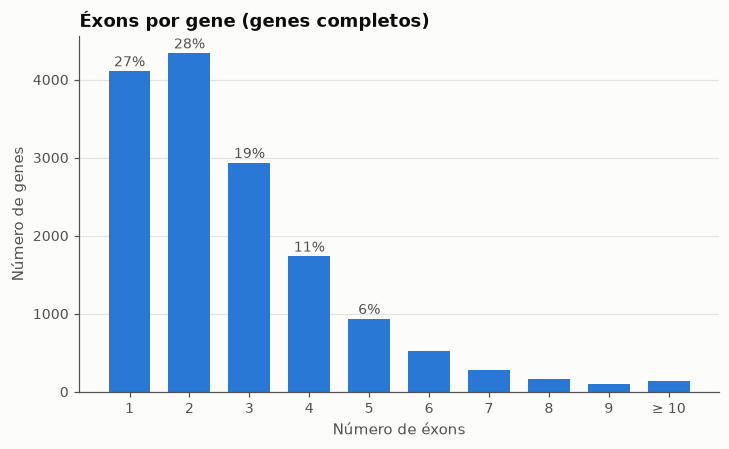

In [15]:
fig, ax = plt.subplots()
ax.bar(rotulos_ex, contagem.values, color=AZUL, width=0.7)
pct = 100 * contagem.values / contagem.sum()
for x, (v, p) in enumerate(zip(contagem.values, pct)):
    if p >= 5:
        ax.annotate(f"{p:.0f}%", (x, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", color=TINTA_2, fontsize=9)
ax.set_xlabel("Número de éxons")
ax.set_ylabel("Número de genes")
ax.set_title("Éxons por gene (genes completos)")
ax.grid(axis="x", visible=False)
salvar(fig, "03_exons_por_gene")
plt.show()

**Resultado**

- **27% dos genes não têm íntrons** (1 éxon) e 28% têm um único íntron (2 éxons): mais da metade dos genes (55%)
  tem no máximo dois éxons.
- A frequência cai rápido: 19% com 3 éxons, 11% com 4, e só 0,9% (136 genes) com 10 ou mais. O máximo é 18.
- Média de 2,76 e mediana de 2 éxons por gene. É uma arquitetura compacta, típica de fungos filamentosos; para
  comparação, o portal MycoCosm (JGI) informa média de 2,66 e mediana de 2 para a linhagem IMI 504890.

### 5.2 Tamanhos: gene, CDS e proteína

Resumimos três medidas para os genes completos:

- **gene**: extensão no genoma, incluindo íntrons;
- **CDS**: só a parte codificadora;
- **proteína**: número de aminoácidos.

Usamos a **mediana** além da média: em distribuições assimétricas (alguns genes muito longos), a média é puxada para
cima e a mediana representa melhor o gene "típico". Os quartis (25% e 75%) mostram a faixa onde está a metade
central dos genes.

In [16]:
def resumo_dist(serie):
    q = serie.quantile([0.25, 0.5, 0.75])
    return pd.Series({"mínimo": serie.min(), "25%": q[0.25], "mediana": q[0.5], "média": serie.mean(),
                      "75%": q[0.75], "máximo": serie.max()}).round(0).astype(int)

tamanhos = pd.DataFrame({
    "gene (pb)": resumo_dist(completos["tam_gene"]),
    "CDS (pb)": resumo_dist(completos["tam_cds"]),
    "proteína (aa)": resumo_dist(completos["tam_proteina"]),
}).T
tamanhos

,mínimo,25%,mediana,média,75%,máximo
gene (pb),66,826,1332,1547,1935,28555
CDS (pb),66,708,1182,1393,1746,28416
proteína (aa),21,235,393,463,581,9471


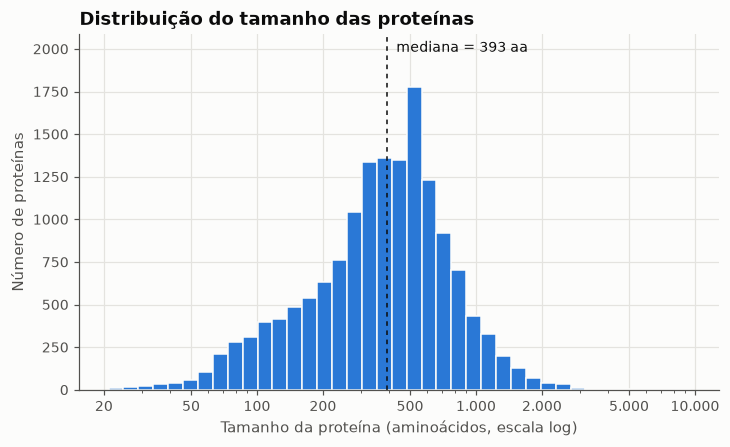

In [17]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(completos["tam_proteina"].min()), np.log10(completos["tam_proteina"].max()), 40)
ax.hist(completos["tam_proteina"], bins=bins, color=AZUL, edgecolor=FUNDO, linewidth=1)
eixo_log(ax, compacto=False)
marcar_mediana(ax, completos["tam_proteina"].median(), "aa")
ax.set_xlabel("Tamanho da proteína (aminoácidos, escala log)")
ax.set_ylabel("Número de proteínas")
ax.set_title("Distribuição do tamanho das proteínas")
salvar(fig, "03_tamanho_proteinas")
plt.show()

**Resultado**

- **Gene típico:** 1.332 pb no genoma (mediana), com CDS de 1.182 pb. Como os íntrons são poucos e curtos, o gene é
  só ~13% maior que a sua CDS.
- **Proteína típica:** 393 aminoácidos (mediana); metade das proteínas tem entre 235 e 581 aa. A média (463 aa) é
  maior que a mediana porque a distribuição tem uma cauda de proteínas muito longas.
- No histograma em escala log, a distribuição é aproximadamente simétrica em torno de 400–500 aa: o tamanho das
  proteínas segue, grosso modo, uma distribuição log-normal, como em outros genomas.
- Para comparação, o MycoCosm informa mediana de 356 aa e média de 430 aa para a IMI 504890: os genes da Ca142 são
  um pouco mais longos e menos numerosos (15.499 contra 17.280), o que é compatível com diferenças de método de
  anotação (uma anotação que prediz mais genes curtos tem mais genes e mediana menor).

**Atenção aos extremos:** a menor proteína tem 21 aa e a maior, 9.471 aa. A célula abaixo examina as duas pontas.

In [18]:
curtas = pd.Series({f"menos de {lim} aa": int((completos["tam_proteina"] < lim).sum()) for lim in (50, 100)},
                   name="proteínas")
display(curtas.to_frame().assign(**{"%": lambda t: (100 * t["proteínas"] / len(completos)).round(1)}))

print("As 5 maiores proteínas:")
completos.nlargest(5, "tam_proteina")[["locus_tag", "tam_proteina", "n_exons", "produto"]]

,proteínas,%
menos de 50 aa,150,1.0
menos de 100 aa,1066,7.0


As 5 maiores proteínas:


,locus_tag,tam_proteina,n_exons,produto
687,CABS02_00688,9471,4,UbiD family decarboxylase
12886,CABS02_12884,8269,4,hypothetical protein
7941,CABS02_07945,4984,1,ATPase
10439,CABS02_10410,4892,6,amino acid adenylation domain-containing protein
4694,CABS02_04696,4692,1,hypothetical protein


**Resultado**

**Proteínas curtas**

- **150 proteínas (1,0%) têm menos de 50 aminoácidos.** São suspeitas: podem ser peptídeos reais, mas muitas vezes
  são fragmentos de genes ou predições espúrias. O caderno 06 mostra que 97% delas são hipotéticas e que nenhuma
  corresponde a um gene conservado (BUSCO). Ficam marcadas na tabela final.
- **1.066 proteínas (7,0%) têm menos de 100 aminoácidos.** As de 50 a 100 aa merecem menos desconfiança: fungos
  fitopatogênicos têm muitas proteínas secretadas pequenas (efetores).

**Proteínas gigantes**

- **`CABS02_00688`, 9.471 aa, "UbiD family decarboxylase":** o nome não combina com o tamanho. As descarboxilases da
  família UbiD têm cerca de 500 aa. Ou o modelo fundiu vários genes vizinhos, ou é uma proteína gigante que recebeu
  o nome de um dos seus domínios. Merece conferência antes de qualquer uso.
- **`CABS02_10410`, 4.892 aa, "amino acid adenylation domain-containing protein":** o domínio de adenilação é a marca
  das sintetases de peptídeos não ribossomais (NRPS), enzimas modulares do metabolismo secundário que de fato têm
  milhares de aminoácidos.
- **`CABS02_07945`, 4.984 aa, "ATPase", em um único éxon:** tamanho compatível com ATPases gigantes conhecidas, como
  a midasina.
- As outras duas (8.269 e 4.692 aa) são hipotéticas.

Dois dos cinco maiores genes não têm íntrons, e os outros têm de 4 a 6 éxons: os genes muito longos deste genoma
não são longos por terem muitos íntrons.

### 5.3 Íntrons

Os íntrons são os intervalos entre éxons consecutivos de um mesmo mRNA. Para cada mRNA, ordenamos os éxons pela
posição e calculamos o espaço entre o fim de um e o início do seguinte:

```
éxon 1          íntron           éxon 2
[======]------------------------[======]
      fim                       início
     íntron = de (fim + 1) até (início − 1)
```

Em fungos filamentosos, os íntrons costumam ser **curtos** (em geral entre 50 e 100 pb), bem menores que os de
plantas e animais.

In [19]:
ex = exons[["Parent", "seqid", "start", "end", "strand"]].sort_values(["Parent", "start"])
ex["prox_inicio"] = ex.groupby("Parent")["start"].shift(-1)       # início do éxon seguinte no mesmo mRNA

introns = ex.dropna(subset=["prox_inicio"]).copy()
introns["inicio"] = introns["end"] + 1
introns["fim"] = introns["prox_inicio"].astype(int) - 1
introns["tamanho"] = introns["fim"] - introns["inicio"] + 1
introns = introns.rename(columns={"Parent": "mrna_id", "strand": "fita"})[
    ["mrna_id", "seqid", "inicio", "fim", "fita", "tamanho"]].reset_index(drop=True)

# só íntrons de genes completos nas estatísticas
introns = introns.merge(genes[["mrna_id", "locus_tag", "parcial"]], on="mrna_id", how="left")
introns_comp = introns[~introns["parcial"]]

print(f"Íntrons: {fmt(len(introns))} (em genes completos: {fmt(len(introns_comp))})")
display(resumo_dist(introns_comp["tamanho"]).to_frame("íntron (pb)").T)
print(f"Íntrons com menos de 100 pb: {100 * (introns_comp['tamanho'] < 100).mean():.1f}%")

Íntrons: 27.371 (em genes completos: 26.937)


,mínimo,25%,mediana,média,75%,máximo
íntron (pb),18,55,63,87,82,2915


Íntrons com menos de 100 pb: 83.0%


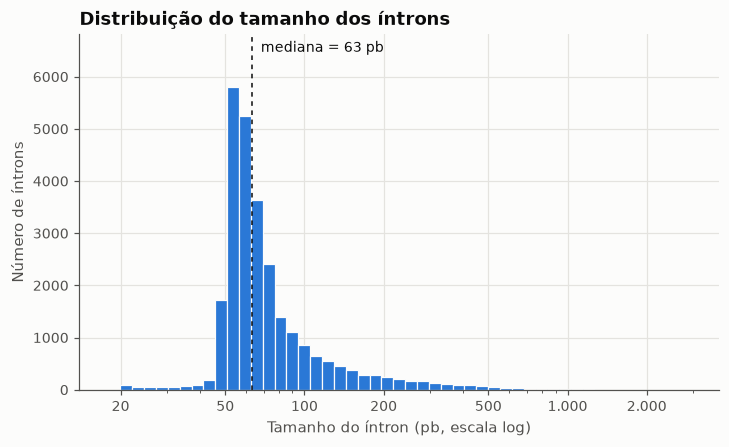

In [20]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(max(introns_comp["tamanho"].min(), 10)), np.log10(introns_comp["tamanho"].max()), 50)
ax.hist(introns_comp["tamanho"], bins=bins, color=AZUL, edgecolor=FUNDO, linewidth=0.8)
eixo_log(ax, compacto=False)
marcar_mediana(ax, introns_comp["tamanho"].median(), "pb")
ax.set_xlabel("Tamanho do íntron (pb, escala log)")
ax.set_ylabel("Número de íntrons")
ax.set_title("Distribuição do tamanho dos íntrons")
salvar(fig, "03_tamanho_introns")
plt.show()

**Resultado**

- **27.371 íntrons** (26.937 em genes completos), o mesmo número deduzido no caderno 02.
- **Os íntrons são curtos e de tamanho muito regular:** mediana de **63 pb**, metade entre 55 e 82 pb, e 83% com
  menos de 100 pb. O histograma tem um pico estreito entre 50 e 70 pb. É o padrão de fungos filamentosos; o MycoCosm
  informa mediana de 66 pb para a IMI 504890.
- **Cauda longa:** a média (87 pb) é maior que a mediana por causa de poucos íntrons longos, até 2.915 pb.
- **Íntrons muito curtos:** o mínimo é 18 pb, e o histograma mostra um pequeno grupo em torno de 20 pb. Íntrons com
  menos de ~40 pb são raros em fungos filamentosos (o spliceossomo precisa de espaço entre o sítio doador, o ponto de
  ramificação e o sítio aceptor) e podem indicar modelos de genes com problema. A seção 5.5 conta quantos são.

### 5.4 Bordas dos íntrons (sítios de splicing)

A maquinaria de splicing reconhece sequências nas bordas do íntron. Na grande maioria dos íntrons de eucariotos,
o íntron **começa com GT** (sítio doador, 5') e **termina com AG** (sítio aceptor, 3') — a regra **GT–AG**.
Uma minoria usa **GC–AG**, e uma fração muito pequena usa **AT–AC**.

Conferir isso é um bom teste da qualidade da anotação: se uma fração grande dos íntrons não seguir essas regras,
os modelos de genes provavelmente têm éxons mal delimitados.

Usamos o dicionário `genoma` da seção 2 para extrair a sequência de cada íntron. Para genes na fita negativa (`-`),
a sequência precisa ser o **complemento reverso** do trecho do genoma, pois o gene é lido na outra fita.

In [21]:
def seq_intron(linha):
    s = genoma[linha.seqid][linha.inicio - 1:linha.fim]      # Python conta a partir de 0
    return str(Seq(s).reverse_complement()) if linha.fita == "-" else s

bordas = Counter()
for linha in introns_comp.itertuples():
    s = seq_intron(linha)
    bordas[f"{s[:2]}–{s[-2:]}"] += 1

tabela_bordas = pd.DataFrame(bordas.most_common(), columns=["doador–aceptor", "íntrons"]).set_index("doador–aceptor")
tabela_bordas["%"] = (100 * tabela_bordas["íntrons"] / tabela_bordas["íntrons"].sum()).round(2)
tabela_bordas.head(8)

,íntrons,%
doador–aceptor,,
GT–AG,25492,94.64
GC–AG,204,0.76
GT–AA,138,0.51
GT–TG,102,0.38
AT–AG,90,0.33
GT–AT,76,0.28
GT–AC,75,0.28
GA–AG,63,0.23


**Resultado**

- **94,6% dos íntrons são GT–AG** e 0,8% são GC–AG: juntos, **95,4%** seguem as regras conhecidas.
- **Os outros 4,6% (cerca de 1.240 íntrons) têm bordas não canônicas**, espalhadas por muitas combinações (GT–AA,
  GT–TG, AT–AG, GT–AT…). Quase sempre um dos lados está certo (GT no início ou AG no fim) e o outro não.

**Isso é mais do que o esperado.** Em eucariotos, em geral mais de 98% dos íntrons são GT–AG e cerca de 1% são
GC–AG. Um excesso de bordas não canônicas, com um lado certo e o outro errado, indica que parte dos modelos de genes
tem **uma das bordas do íntron mal posicionada** por alguns nucleotídeos.

O que isso significa na prática:

- a anotação é boa no geral (95% dos íntrons seguem a regra, e o quadro de leitura está preservado em todos os genes
  completos, como mostrou a seção 4.1);
- nos genes afetados, a proteína predita pode ter alguns aminoácidos errados perto da junção, e a CDS anotada pode
  incluir um pedaço de íntron ou omitir um pedaço de éxon;
- para o RNAi, um dsRNA desenhado sobre uma junção mal anotada perderia parte da complementaridade com o mRNA real.
  Vale preferir genes sem íntrons não canônicos ou desenhar o dsRNA dentro de um único éxon.

O código foi conferido: um erro no tratamento da fita negativa apareceria como um excesso de `CT–AC` (o complemento
reverso de GT–AG), que não está na tabela.

### 5.5 Quais genes têm íntrons não canônicos?

Marcamos cada íntron como canônico (GT–AG, GC–AG ou AT–AC, este último próprio de uma classe rara de íntrons) ou não
canônico, e contamos quantos genes têm pelo menos um íntron não canônico. Também cruzamos com o tamanho do íntron,
para ver se os íntrons muito curtos são os problemáticos.

In [22]:
CANONICAS = {"GT–AG", "GC–AG", "AT–AC"}

def bordas_intron(linha):
    s = seq_intron(linha)
    return f"{s[:2]}–{s[-2:]}"

introns["bordas"] = [bordas_intron(linha) for linha in introns.itertuples()]
introns["canonico"] = introns["bordas"].isin(CANONICAS)
introns["classe_tamanho"] = pd.cut(introns["tamanho"], [0, 40, 100, np.inf],
                                   labels=["menos de 40 pb", "40 a 99 pb", "100 pb ou mais"], right=False)
introns_comp = introns[~introns["parcial"]]

por_tamanho = introns_comp.groupby("classe_tamanho", observed=False).agg(
    introns=("canonico", "size"), nao_canonicos=("canonico", lambda c: int((~c).sum())))
por_tamanho["% não canônicos"] = (100 * por_tamanho["nao_canonicos"] / por_tamanho["introns"]).round(1)
por_tamanho

,introns,nao_canonicos,% não canônicos
classe_tamanho,,,
menos de 40 pb,415,298,71.8
40 a 99 pb,21951,629,2.9
100 pb ou mais,4571,310,6.8


In [23]:
nc_por_gene = introns[~introns["canonico"]].groupby("mrna_id").size()
menor_intron = introns.groupby("mrna_id")["tamanho"].min()
genes["n_introns_nc"] = genes["mrna_id"].map(nc_por_gene).fillna(0).astype(int)
genes["menor_intron"] = genes["mrna_id"].map(menor_intron).astype("Int64")
completos = genes[~genes["parcial"]].copy()

com_introns = completos[completos["n_exons"] > 1]
afetados = (completos["n_introns_nc"] > 0).sum()
print(f"Genes completos com íntrons: {fmt(len(com_introns))}")
print(f"  com pelo menos um íntron não canônico: {fmt(afetados)} "
      f"({100 * afetados / len(com_introns):.1f}% dos genes com íntrons, {100 * afetados / len(completos):.1f}% de todos)")
print(f"  com algum íntron de menos de 40 pb:    {fmt((com_introns['menor_intron'] < 40).sum())}")

Genes completos com íntrons: 11.171
  com pelo menos um íntron não canônico: 1.113 (10.0% dos genes com íntrons, 7.3% de todos)
  com algum íntron de menos de 40 pb:    379


**Resultado: os íntrons muito curtos são, em sua maioria, artefatos.**

| Tamanho do íntron | Íntrons | Não canônicos |
|---|---|---|
| menos de 40 pb | 415 | **72%** |
| 40 a 99 pb | 21.951 | 2,9% |
| 100 pb ou mais | 4.571 | 6,8% |

- **Três em cada quatro íntrons com menos de 40 pb têm bordas não canônicas.** Não são íntrons reais mal
  delimitados: provavelmente são "saltos" que o programa de predição inseriu para contornar um códon de parada ou
  uma mudança de fase na sequência. Onde isso acontece, a causa pode ser um erro de sequência na montagem ou um gene
  que de fato está inativado.
- **Na faixa típica (40 a 99 pb), só 2,9% são não canônicos**, um valor próximo do esperado. É nessa faixa que estão
  81% dos íntrons.
- **Os íntrons longos (100 pb ou mais) voltam a ter mais problemas** (6,8%): bordas mal posicionadas são mais
  prováveis quando o íntron foge do tamanho habitual.
- Sem os íntrons de menos de 40 pb, a taxa geral de não canônicos cai de 4,6% para 3,5%.

**Genes afetados**

- **1.113 genes** têm pelo menos um íntron não canônico: 10,0% dos genes com íntrons e 7,3% de todos os genes
  completos.
- **379 genes** têm algum íntron de menos de 40 pb.

As colunas `n_introns_nc` e `menor_intron` entram na tabela de genes salva na seção 8, e o caderno 06 as usa como
alertas de qualidade do modelo.

## 6. Proteínas

### 6.1 Proteínas com função atribuída

O atributo `product` traz o nome da proteína. Quando a anotação não encontrou semelhança com proteínas conhecidas,
o nome é **"hypothetical protein"** (proteína hipotética). A fração de proteínas hipotéticas indica quanto do
genoma ainda é "desconhecido" — em fungos fitopatogênicos, isso costuma ser alto e inclui muitos **efetores**
(proteínas secretadas que interagem com a planta), frequentemente exclusivos de cada espécie.

In [24]:
hipotetica = completos["produto"].fillna("").str.contains("hypothetical|uncharacterized", case=False)
print(f"Proteínas hipotéticas: {fmt(hipotetica.sum())} de {fmt(len(completos))} ({100 * hipotetica.mean():.1f}%)")

print("\nNomes de produto mais frequentes (excluindo hipotéticas):")
completos.loc[~hipotetica, "produto"].value_counts().head(20).to_frame("genes")

Proteínas hipotéticas: 8.115 de 15.284 (53.1%)

Nomes de produto mais frequentes (excluindo hipotéticas):


,genes
produto,
major facilitator superfamily transporter,232
cytochrome P450,107
FAD binding domain-containing protein,82
fungal specific transcription factor domain-containing protein,72
integral membrane protein,70
short-chain dehydrogenase,57
methyltransferase domain-containing protein,49
WD domain-containing protein,47
F-box domain-containing protein,44


**Resultado**

- **53,1% das proteínas (8.115) são hipotéticas:** não têm função atribuída. É uma proporção comum em fungos
  fitopatogênicos, e lembra que mais da metade do proteoma ainda é desconhecida.
- **As famílias mais frequentes** são transportadores e enzimas: transportadores MFS (232), citocromos P450 (107),
  proteínas com domínio de ligação a FAD (82), fatores de transcrição específicos de fungos, desidrogenases de cadeia
  curta e transportadores ABC. São famílias ligadas a transporte, detoxificação e metabolismo secundário, e
  costumam ser grandes em *Colletotrichum*.
- **Os nomes não são padronizados.** A mesma família aparece com grafias diferentes e é contada em linhas separadas:
  "short-chain dehydrogenase" (57) e "short chain dehydrogenase" (37); "fungal specific transcription factor
  domain-containing protein" (72) e "fungal specific transcription factor" (40); "WD domain-containing protein" (47) e
  "WD repeat domain-containing protein" (31). Por isso, contar por nome **subestima** o tamanho das famílias.

Consequência: buscas por nome de produto (como as do caderno 06) servem para localizar genes, mas uma contagem
confiável de famílias exige anotação por domínios (Pfam/InterPro), que fica para a etapa de anotação funcional.

### 6.2 Composição de aminoácidos

A frequência de cada aminoácido no conjunto de proteínas (o *proteoma*). Serve mais como referência do que como
resultado: proteomas de fungos têm composição característica, e desvios grandes em proteínas individuais (por
exemplo, muito ricas em cisteína) são uma pista usada para identificar efetores.

In [25]:
composicao = Counter()
for p in completos["protein_id"]:
    composicao.update(seq_prot.get(p, "").rstrip("*"))
comp = pd.Series(composicao).drop(labels=["X", "*"], errors="ignore")
comp = (100 * comp / comp.sum()).sort_values(ascending=False).round(2)
comp.to_frame("% no proteoma").T

,A,L,S,G,V,T,P,E,R,D,I,K,Q,F,N,Y,H,M,W,C
% no proteoma,9.04,8.69,8.1,7.14,6.27,6.12,6.07,5.99,5.96,5.68,4.79,4.76,3.89,3.77,3.64,2.71,2.33,2.22,1.55,1.28


**Resultado:** os aminoácidos mais frequentes são alanina (9,0%), leucina (8,7%), serina (8,1%) e glicina (7,1%);
os mais raros, cisteína (1,3%), triptofano (1,5%), metionina (2,2%) e histidina (2,3%). É a composição habitual de
proteomas de ascomicetos, sem nada fora do comum. A tabela serve como referência: a cisteína média de 1,3%, por
exemplo, é a base para reconhecer proteínas pequenas ricas em cisteína, um perfil comum entre efetores.

## 7. Genes ao longo do genoma

Contamos os genes de cada scaffold e calculamos a **densidade gênica** (genes por Mb). Duas perguntas:

1. **Há scaffolds sem nenhum gene?** Quantos são, de que tamanho e com que conteúdo GC?
2. **A densidade gênica tem relação com o GC?**

Em várias espécies de *Colletotrichum*, o genoma tem regiões **pobres em genes e ricas em AT** (GC baixo), associadas
a elementos repetitivos (transposons). Um mecanismo de defesa dos fungos contra transposons, o **RIP**
(*repeat-induced point mutation*), troca C por T em sequências repetidas e, ao longo do tempo, reduz o GC dessas
regiões. Esses trechos repetitivos também são difíceis de montar com leituras curtas — por isso muitas vezes
terminam como scaffolds pequenos.

In [26]:
genes_por_scaf = genes.groupby("seqid").size().rename("n_genes")
df_scaf = df_scaf.drop(columns="n_genes", errors="ignore").merge(
    genes_por_scaf, left_on="scaffold", right_index=True, how="left")
df_scaf["n_genes"] = df_scaf["n_genes"].fillna(0).astype(int)
df_scaf["genes_por_mb"] = df_scaf["n_genes"] / (df_scaf["tamanho"] / 1e6)
df_scaf["tem_genes"] = df_scaf["n_genes"] > 0

grupos = df_scaf.groupby("tem_genes").agg(
    scaffolds=("tamanho", "size"), pb=("tamanho", "sum"),
    tamanho_mediano=("tamanho", "median"), gc_mediano=("gc", "median"))
grupos.index = grupos.index.map({True: "com genes", False: "sem genes"})
grupos["% do genoma"] = (100 * grupos["pb"] / TOTAL).round(1)
grupos["gc_mediano"] = (100 * grupos["gc_mediano"]).round(1)
grupos

,scaffolds,pb,tamanho_mediano,gc_mediano,% do genoma
tem_genes,,,,,
sem genes,38,85360,1537.5,50.0,0.2
com genes,385,53916536,60923.0,52.5,99.8


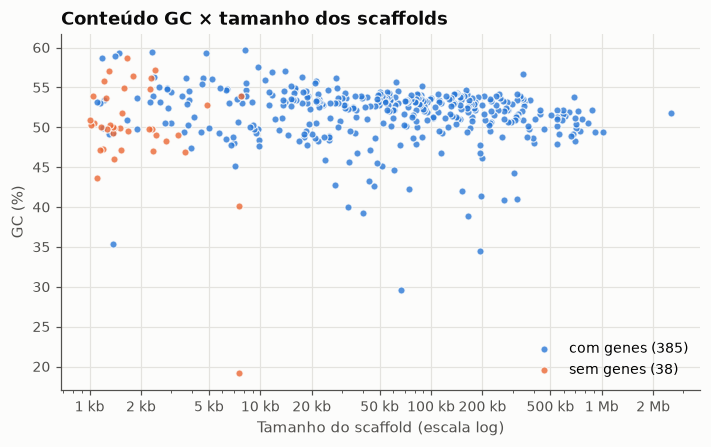

In [27]:
fig, ax = plt.subplots()
for tem, cor, rotulo in [(True, AZUL, "com genes"), (False, LARANJA, "sem genes")]:
    sub = df_scaf[df_scaf["tem_genes"] == tem]
    ax.scatter(sub["tamanho"], 100 * sub["gc"], s=22, color=cor, alpha=0.8,
               edgecolor=FUNDO, linewidth=0.8, label=f"{rotulo} ({len(sub)})")
eixo_log(ax)
ax.set_xlabel("Tamanho do scaffold (escala log)")
ax.set_ylabel("GC (%)")
ax.set_title("Conteúdo GC × tamanho dos scaffolds")
ax.legend(loc="lower right")
salvar(fig, "03_gc_tamanho_scaffolds")
plt.show()

**Resultado**

- **38 scaffolds não têm nenhum gene, mas somam só 85 kb (0,2% do genoma).**
- **Eles são pequenos demais para ter genes:** a mediana é de 1,5 kb, pouco mais que um gene típico (1,3 kb). No
  gráfico, todos os pontos laranja estão abaixo de 10 kb.
- **O GC deles não é claramente mais baixo:** mediana de 50,0%, contra 52,5% nos scaffolds com genes, e muito
  disperso (de 19% a 59%). A hipótese de que os scaffolds sem genes seriam regiões ricas em AT **não se confirma**:
  o que explica a ausência de genes é o tamanho.
- **O sinal interessante está em outro lugar:** entre os scaffolds **com** genes, há um grupo de tamanho médio
  (30 a 300 kb) com GC bem abaixo do resto, entre 30% e 45%. A nuvem principal fica entre 48% e 56%, e se estreita em
  torno de 50–52% nos scaffolds maiores, como se espera de uma média sobre mais bases.
- A dispersão do GC cresce nos scaffolds pequenos: em 1 ou 2 kb, o GC reflete o conteúdo local (um trecho de gene,
  uma repetição), não a média do genoma.

Para a relação entre densidade gênica e GC, usamos só scaffolds de **pelo menos 50 kb**: em scaffolds muito
pequenos, um único gene a mais ou a menos muda muito a densidade, e o ponto vira ruído.

A **correlação de Spearman** mede se as duas grandezas sobem (ou descem) juntas, sem exigir uma relação linear.
Vai de −1 a +1; perto de 0, não há relação. Ela é calculada trocando cada valor pela sua posição na ordem
(o menor vira 1, o seguinte 2…) e medindo a correlação comum entre essas posições.

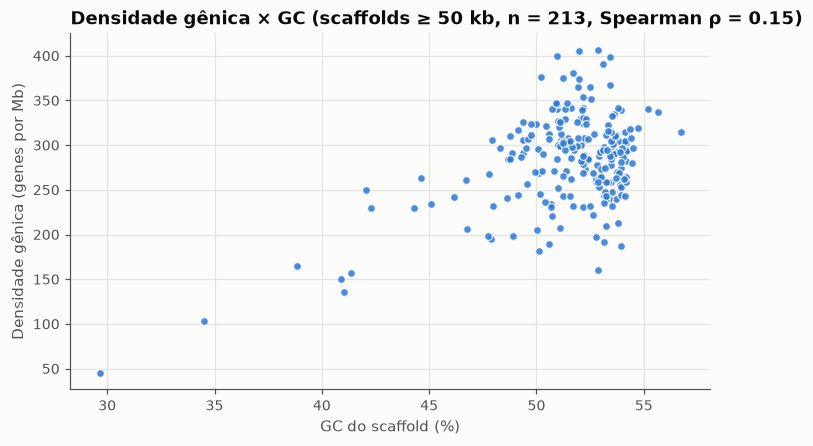

Densidade média no genoma: 287 genes por Mb


In [28]:
grandes = df_scaf[df_scaf["tamanho"] >= 50_000]
# Spearman = correlação de Pearson calculada sobre as posições (postos) dos valores
rho = grandes["gc"].rank().corr(grandes["genes_por_mb"].rank())

fig, ax = plt.subplots()
ax.scatter(100 * grandes["gc"], grandes["genes_por_mb"], s=26, color=AZUL, alpha=0.85,
           edgecolor=FUNDO, linewidth=0.8)
ax.set_xlabel("GC do scaffold (%)")
ax.set_ylabel("Densidade gênica (genes por Mb)")
ax.set_title(f"Densidade gênica × GC (scaffolds ≥ 50 kb, n = {len(grandes)}, Spearman ρ = {rho:.2f})")
salvar(fig, "03_densidade_gc")
plt.show()

media_genoma = len(genes) / (TOTAL / 1e6)
print(f"Densidade média no genoma: {media_genoma:.0f} genes por Mb")

**Resultado**

- **Densidade média: 287 genes por Mb**, ou um gene a cada ~3,5 kb.
- **A correlação no conjunto é fraca** (ρ de Spearman = 0,15, em 213 scaffolds). Na nuvem principal (GC entre 48% e
  55%), a densidade varia de ~160 a ~400 genes por Mb sem relação visível com o GC.
- **A relação aparece só na cauda:** os seis scaffolds com GC abaixo de 42% têm entre 45 e 165 genes por Mb, metade
  da média ou menos. São poucos pontos, e por isso pesam pouco numa correlação calculada sobre todos os scaffolds.

**Conclusão:** existem regiões ricas em AT e pobres em genes, mas a média por scaffold é uma medida grosseira para
encontrá-las. Um scaffold de 500 kb pode conter um trecho rico em AT de 50 kb sem que o seu GC médio mude muito. O
caderno `04_composicao_ca142.ipynb` refaz essa análise em **janelas** ao longo dos scaffolds e testa se essas regiões
têm a assinatura de RIP.

## 8. Tabelas salvas

Salvamos em `data/processed/` as três tabelas construídas, em formato TSV (texto separado por tabulações), que
abre no pandas, em planilhas e em qualquer editor de texto:

| Arquivo | Uma linha por | Uso futuro |
|---|---|---|
| `ca142_scaffolds.tsv` | scaffold | tamanho, GC, número e densidade de genes |
| `ca142_genes.tsv` | gene | estrutura, tamanhos, produto, se é parcial, íntrons não canônicos — **ponto de partida para a seleção de alvos** |
| `ca142_introns.tsv` | íntron | posição, tamanho, bordas e se é canônico |

Os gráficos estão em `results/figures/`.

In [29]:
colunas_genes = ["locus_tag", "gene_id", "mrna_id", "protein_id", "seqid", "inicio", "fim", "fita",
                 "n_exons", "tam_gene", "tam_cds", "tam_proteina", "tam_introns", "n_introns_nc", "menor_intron",
                 "parcial", "produto"]

saidas = {
    "ca142_scaffolds.tsv": df_scaf.drop(columns=["acumulado", "posto"]),
    "ca142_genes.tsv": genes[colunas_genes],
    "ca142_introns.tsv": introns,
}
for nome, tabela in saidas.items():
    tabela.to_csv(DIR_PROC / nome, sep="\t", index=False)
    print(f"{nome:22s} {fmt(len(tabela)):>7s} linhas")

print("\nFiguras:", ", ".join(sorted(p.name for p in DIR_FIG.glob("03_*.png"))))

ca142_scaffolds.tsv        423 linhas
ca142_genes.tsv         15.499 linhas
ca142_introns.tsv       27.371 linhas

Figuras: 03_curva_nx.png, 03_densidade_gc.png, 03_exons_por_gene.png, 03_gc_tamanho_scaffolds.png, 03_tamanho_introns.png, 03_tamanho_proteinas.png, 03_tamanho_scaffolds.png


## 9. Síntese e próximos passos

A célula abaixo reúne os principais números deste caderno em uma tabela.

In [30]:
sintese = pd.Series(dtype="object", data={
    "Scaffolds": fmt(len(df_scaf)),
    "Tamanho total": f"{TOTAL / 1e6:.2f} Mb",
    "N50 / L50": f"{fmt(n50)} pb / {l50}",
    "N90 / L90": f"{fmt(n90)} pb / {l90}",
    "GC": f"{100 * (df_scaf['G'].sum() + df_scaf['C'].sum()) / df_scaf[['A','C','G','T']].sum().sum():.1f}%",
    "Genes (completos / parciais)": f"{fmt(len(completos))} / {fmt(genes['parcial'].sum())}",
    "Genes sem íntrons": f"{100 * (completos['n_exons'] == 1).mean():.1f}%",
    "Éxons por gene (média)": f"{completos['n_exons'].mean():.2f}",
    "Proteína (mediana)": f"{completos['tam_proteina'].median():.0f} aa",
    "Íntron (mediana)": f"{introns_comp['tamanho'].median():.0f} pb",
    "Íntrons GT–AG": f"{tabela_bordas['%'].get('GT–AG', 0):.1f}%",
    "Proteínas hipotéticas": f"{100 * hipotetica.mean():.1f}%",
    "Scaffolds sem genes": f"{(~df_scaf['tem_genes']).sum()} ({grupos.loc['sem genes', '% do genoma'] if 'sem genes' in grupos.index else 0}% do genoma)",
    "Densidade gênica × GC (ρ)": f"{rho:.2f}",
})
sintese.to_frame("Ca142")

,Ca142
Scaffolds,423
Tamanho total,54.00 Mb
N50 / L50,321.765 pb / 46
N90 / L90,74.130 pb / 177
GC,51.1%
Genes (completos / parciais),15.284 / 215
Genes sem íntrons,26.9%
Éxons por gene (média),2.76
Proteína (mediana),393 aa
Íntron (mediana),63 pb


## Conclusões deste caderno

**Montagem**

- Metade do genoma está em 46 scaffolds (N50 de 322 kb) e 90% em 177. Os 105 scaffolds com menos de 10 kb somam só
  0,8% das bases.

**Anotação**

- **É internamente consistente:** nos 15.284 genes completos, GFF, CDS e proteínas concordam em 100% dos casos.
- **Não tem UTRs nem isoformas:** só a região codificadora de um transcrito por gene.
- **215 genes (1,4%) são parciais**, quase todos sem o códon de início. Em 79% deles a causa é o modelo de gene, e
  não a fragmentação da montagem: estão no interior dos scaffolds.
- **4,6% dos íntrons têm bordas não canônicas**, mais que o esperado. O problema se concentra nos 415 íntrons com
  menos de 40 pb (72% não canônicos), que parecem artefatos da predição. Ao todo, 1.113 genes têm pelo menos um
  íntron não canônico; a coluna `n_introns_nc` os marca.
- **150 proteínas têm menos de 50 aa**, e a maior proteína (9.471 aa) tem um nome que não combina com o tamanho.

**Genes e proteínas**

- Genes compactos: 2,76 éxons por gene, 27% sem íntrons, íntrons de 63 pb (mediana), proteína de 393 aa (mediana).
- 53% das proteínas são hipotéticas, e os nomes de produto não são padronizados.

**Organização**

- 287 genes por Mb. Os scaffolds sem genes são apenas pequenos demais. Alguns scaffolds de tamanho médio têm GC
  baixo (30–45%) e poucos genes: o caderno 04 investiga essas regiões.

**Para a escolha de alvos de RNAi**, este caderno já dá três filtros objetivos: usar genes **completos**, **sem
íntrons não canônicos**, e desenhar o dsRNA sobre a **CDS** (a única parte do transcrito que a anotação traz).

**Próximos cadernos**

1. `04_composicao_ca142.ipynb`: GC em janelas, regiões ricas em AT, sinais de RIP e organização dos genes.
2. `05_completude_busco_ca142.ipynb`: completude do conjunto de genes (BUSCO).
3. `06_sintese_ca142.ipynb`: síntese e tabela final de genes, com a confiabilidade de cada modelo.